# 01. 데이터 수집 — 서울 아파트 실거래가 최근 5년

**데이터 출처**: 국토교통부 아파트매매 실거래상세자료 (공공데이터포털 Open API)

이 노트북의 목표는 **서울 25개 구의 아파트 매매 실거래 데이터를 최근 60개월(5년)** 수집해서,
`02_eda_feature_engineering_5year.ipynb`가 바로 사용할 수 있는 parquet 파일로 저장하는 것입니다.

### V2(5년) 변경점
- 전국 267개 시군구 수집 → **서울 25개 구만 수집**
- 최근 12개월 → **최근 60개월**
- 기존 1년 raw 체크포인트와 섞이지 않도록 **별도 폴더** 사용
- 최신 신고 지연을 고려해 기본값은 **최근 2개월을 제외한 완결 월까지** 수집
- 기존 `apt_trade_raw.parquet`가 있다면 최초 실행 시 1년 백업을 남김
- 버전 파일 `apt_trade_raw_5y.parquet`와 하위 노트북 호환용 `apt_trade_raw.parquet`를 함께 저장


## 1. 사전 준비 — API 인증키 발급 방법

### 1) 공공데이터포털 회원가입
- https://www.data.go.kr 접속 → 우측 상단 **회원가입** (개인 회원으로 충분)

### 2) API 검색 및 활용신청
- 로그인 후 검색창에 **"아파트 매매 실거래가 상세 자료"** 검색
- **정확한 데이터셋명: `국토교통부_아파트 매매 실거래가 상세 자료` (data.go.kr ID: 15126468, 엔드포인트: `RTMSDataSvcAptTradeDev`)**
  - 이름이 비슷한 `국토교통부_아파트 매매 실거래가 자료` (ID: 15126469, "상세"가 빠진 이름, 엔드포인트: `RTMSDataSvcAptTrade`)는 **필드 수가 더 적은 구버전**이므로 헷갈리지 않도록 주의. 이 노트북은 **"상세 자료"(15126468, `...Dev`)** 기준.
- 상세 페이지에서 **활용신청** 클릭 후 간단한 정보 입력 (심의 없이 자동 승인되는 경우가 대부분)

### 3) 승인 대기 및 키 확인
- 보통 1~2시간 이내 자동 승인
- 승인 후 **마이페이지 → 데이터활용 → 개발계정**에서 서비스키 확인
- **Decoding 키**를 사용 (Encoding 키를 쓰면 이중 인코딩되어 403 에러 발생)

### 4) 트래픽 한도
- 개발계정은 보통 일일 트래픽 한도가 있어서(통상 1,000회 내외), 전국 267개 시군구 × 여러 개월을 수집하려면 한도를 초과할 수 있음 → 아래 수집 코드는 **지역/월 단위 체크포인트 저장**으로 설계 (중단 후 재실행하면 이어서 수집)

### 5) 키 보관 — `.env` 파일 사용
프로젝트 루트에 `.env` 파일을 만들고 아래처럼 작성 (절대 커밋하지 말 것, `.gitignore`에 `.env` 추가):
```
DATA_GO_KR_API_KEY=발급받은_디코딩_키
```


In [ ]:
import os
import time
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ------------------------------------------------------------------
# 설정
# ------------------------------------------------------------------

DEMO_MODE = False
TEST_SUBSET = False

REPORTING_LAG_MONTHS = 2
N_MONTHS = 60

load_dotenv()
SERVICE_KEY = os.environ.get("DATA_GO_KR_API_KEY", "")


# ------------------------------------------------------------------
# 경로 설정
# ------------------------------------------------------------------

# 현재 위치:
# Apartment price/notebook/v2_5year_notebook
PROJECT_DIR = Path.cwd().parents[1]

DATA_ROOT = PROJECT_DIR / "data"

# V2 5년 데이터 전용
DATA_DIR = DATA_ROOT / "v2_5year_seoul"

RAW_DIR = DATA_DIR / "raw" / "trade"
PROCESSED_DIR = DATA_DIR / "processed"

# V1 / V2 공통 외부 데이터
EXTERNAL_DIR = DATA_ROOT / "external"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------------
# 저장 파일
# ------------------------------------------------------------------

RAW_OUTPUT_PATH = PROCESSED_DIR / "apt_trade_raw.parquet"


# ------------------------------------------------------------------
# API 키 체크
# ------------------------------------------------------------------

if not DEMO_MODE and not SERVICE_KEY:
    raise ValueError(
        "DEMO_MODE=False 인데 DATA_GO_KR_API_KEY "
        "환경변수가 비어 있습니다. "
        "서비스키를 환경변수로 설정하거나 "
        "DEMO_MODE=True 로 두세요."
    )


# ------------------------------------------------------------------
# 경로 확인
# ------------------------------------------------------------------

print(f"DEMO_MODE = {DEMO_MODE}")
print(f"TEST_SUBSET = {TEST_SUBSET}")

print("\n[경로 확인]")
print("현재 위치       :", Path.cwd())
print("프로젝트 루트   :", PROJECT_DIR.resolve())
print("DATA_ROOT       :", DATA_ROOT.resolve())
print("DATA_DIR        :", DATA_DIR.resolve())
print("RAW_DIR         :", RAW_DIR.resolve())
print("PROCESSED_DIR   :", PROCESSED_DIR.resolve())
print("EXTERNAL_DIR    :", EXTERNAL_DIR.resolve())
print("RAW_OUTPUT_PATH :", RAW_OUTPUT_PATH.resolve())

DEMO_MODE = False
TEST_SUBSET = False

[경로 확인]
현재 위치       : c:\Users\uk\Apartment price\notebook\v2_5year_notebook
프로젝트 루트   : C:\Users\UK\Apartment price
DATA_ROOT       : C:\Users\UK\Apartment price\data
DATA_DIR        : C:\Users\UK\Apartment price\data\v2_5year_seoul
RAW_DIR         : C:\Users\UK\Apartment price\data\v2_5year_seoul\raw
PROCESSED_DIR   : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed
EXTERNAL_DIR    : C:\Users\UK\Apartment price\data\external
RAW_OUTPUT_PATH : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\apt_trade_raw.parquet


## 2. 지역코드(법정동코드) 조회

Open API는 지역을 5자리 **법정동시군구코드(LAWD_CD)**로 지정합니다.

전국 코드를 받아오되 실제 거래 수집 대상은 **서울특별시 25개 구**로 제한합니다.
`sigungu_map.csv`는 이후 EDA에서 코드 → 시군구명 매핑에 재사용합니다.


In [12]:
import PublicDataReader as pdr


def get_nationwide_sigungu_codes() -> pd.DataFrame:
    """전국 시군구 단위 법정동코드 목록을 반환한다."""
    
    code_df = pdr.code_bdong()

    sgg = code_df[
        (code_df["읍면동명"] == "") &
        (code_df["시군구명"] != "") &
        (code_df["말소일자"] == "")
    ][
        ["시도명", "시군구명", "시군구코드"]
    ].drop_duplicates().reset_index(drop=True)

    sgg["시군구코드"] = (
        sgg["시군구코드"]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )

    return sgg


# 전국 코드 조회
sigungu_df = get_nationwide_sigungu_codes()


# 서울만 추출
seoul_regions = (
    sigungu_df[
        sigungu_df["시도명"] == "서울특별시"
    ]
    .drop_duplicates("시군구코드")
    .reset_index(drop=True)
)


print(f"전국 시군구 수: {len(sigungu_df)}")
print(f"서울 수집 대상 구 수: {len(seoul_regions)}")


# 서울 25개 구 검증
if len(seoul_regions) != 25:
    raise ValueError(
        f"서울 구 수가 25개가 아닙니다. "
        f"현재 {len(seoul_regions)}개"
    )


# V2에서는 서울 코드만 저장
seoul_regions.to_csv(
    PROCESSED_DIR / "sigungu_map.csv",
    index=False,
    encoding="utf-8-sig"
)


display(
    seoul_regions[
        ["시도명", "시군구명", "시군구코드"]
    ]
)

출처: 행정기관(행정동) 및 관할구역(법정동) 변경내역(2024.8.1. 시행)
전국 시군구 수: 267
서울 수집 대상 구 수: 25


,시도명,시군구명,시군구코드
0,서울특별시,종로구,11110
1,서울특별시,중구,11140
2,서울특별시,용산구,11170
3,서울특별시,성동구,11200
4,서울특별시,광진구,11215
5,서울특별시,동대문구,11230
6,서울특별시,중랑구,11260
7,서울특별시,성북구,11290
8,서울특별시,강북구,11305
9,서울특별시,도봉구,11320


## 3. 수집 대상(서울 25개 구 / 최근 60개월) 설정

### 기간 설정 원칙
실거래 신고는 계약 직후 즉시 모두 반영되는 데이터가 아니므로 **최신 월은 거래량이 덜 집계될 수 있습니다.**

기본값은 `REPORTING_LAG_MONTHS = 2`로 두어 현재 시점 기준 전전월까지 수집합니다.

예를 들어 2026년 8월에 실행하면 기본 수집 범위는 대략 **2021년 7월 ~ 2026년 6월, 총 60개월**입니다.

최신성보다 완결성을 덜 중요하게 볼 경우 `REPORTING_LAG_MONTHS`를 1 또는 0으로 조정할 수 있습니다.

`TEST_SUBSET=True`이면 서울 일부 구와 최근 3개월만 먼저 호출해 API/컬럼 구조를 검증합니다.


In [13]:
# 실제 수집 대상
if TEST_SUBSET:
    target_regions = seoul_regions.head(2).copy()
else:
    target_regions = seoul_regions.copy()

# 완결 월 기준 최근 60개월
current_month = pd.Timestamp.today().to_period("M")
END_MONTH = current_month - REPORTING_LAG_MONTHS
START_MONTH = END_MONTH - (N_MONTHS - 1)

full_year_months = [
    str(p).replace("-", "")
    for p in pd.period_range(START_MONTH, END_MONTH, freq="M")
]

if TEST_SUBSET:
    year_months = full_year_months[-3:]
else:
    year_months = full_year_months

print(f"수집 기간: {year_months[0]} ~ {year_months[-1]}")
print(f"대상 지역 수: {len(target_regions)}")
print(f"대상 월 수: {len(year_months)}")
print(f"예상 API 호출 수: {len(target_regions) * len(year_months):,}")


수집 기간: 202107 ~ 202606
대상 지역 수: 25
대상 월 수: 60
예상 API 호출 수: 1,500


## 4. 데이터 수집 함수

- `fetch_real(...)`: 실제 국토부 API 호출
- `fetch_demo(...)`: API 키 없이 구조 테스트용 합성 데이터
- 체크포인트: `data/raw/apartment_seoul_5y/{시군구코드}_{연월}.csv`
- 이미 존재하는 지역×월 파일은 자동으로 건너뛰므로 중단 후 재실행 가능
- **5년용 별도 raw 폴더를 사용하므로 기존 1년 체크포인트와 섞이지 않습니다**


In [16]:
from PublicDataReader import TransactionPrice

if not DEMO_MODE:
    api = TransactionPrice(SERVICE_KEY)


def fetch_real(
    sigungu_code: str,
    year_month: str
) -> pd.DataFrame:
    return api.get_data(
        property_type="아파트",
        trade_type="매매",
        sigungu_code=str(sigungu_code).zfill(5),
        year_month=year_month,
    )


def fetch_demo(
    sigungu_code: str,
    year_month: str,
    n: int = 30,
    seed: int | None = None
) -> pd.DataFrame:

    rng = np.random.default_rng(
        seed or (
            hash((sigungu_code, year_month))
            % (2**32)
        )
    )

    n = int(rng.integers(5, n))
    base_price = rng.uniform(40000, 150000)

    return pd.DataFrame({
        "법정동시군구코드":
            str(sigungu_code).zfill(5),

        "계약년도":
            int(year_month[:4]),

        "계약월":
            int(year_month[4:6]),

        "계약일":
            rng.integers(1, 28, n),

        "전용면적":
            np.round(
                rng.uniform(39, 135, n),
                2
            ),

        "층":
            rng.integers(1, 25, n),

        "건축년도":
            rng.integers(1988, 2025, n),

        "거래금액":
            np.round(
                base_price
                + rng.normal(0, 8000, n)
            ).clip(min=5000),

        "단지명": [
            f"데모아파트{i}"
            for i in rng.integers(1, 20, n)
        ],

        "법정동": "데모동",
        "지번": "1-1",
    })


# ----------------------------------------------------------
# 체크포인트
# ----------------------------------------------------------

def checkpoint_path(
    sigungu_code: str,
    year_month: str
) -> Path:

    return RAW_DIR / (
        f"{str(sigungu_code).zfill(5)}_"
        f"{year_month}.csv"
    )


def expected_checkpoint_paths(
    regions: pd.DataFrame,
    months: list[str]
) -> list[Path]:

    return [
        checkpoint_path(
            row["시군구코드"],
            ym
        )
        for _, row in regions.iterrows()
        for ym in months
    ]


# ----------------------------------------------------------
# 수집
# ----------------------------------------------------------

def collect_transaction_data(
    regions: pd.DataFrame,
    months: list[str],
    sleep_sec: float = 0.2,
    max_retries: int = 3,
) -> None:

    total = len(regions) * len(months)

    done = 0
    skipped = 0
    empty = 0
    failed = []

    for _, row in regions.iterrows():

        sgg_code = str(
            row["시군구코드"]
        ).zfill(5)

        sgg_name = row["시군구명"]

        for ym in months:

            out_path = checkpoint_path(
                sgg_code,
                ym
            )

            done += 1

            # 이미 받은 데이터
            if out_path.exists():
                skipped += 1
                continue


            # ----------------------------------------------
            # API 호출 재시도
            # ----------------------------------------------

            success = False

            for attempt in range(
                1,
                max_retries + 1
            ):

                try:

                    if DEMO_MODE:

                        df = fetch_demo(
                            sgg_code,
                            ym
                        )

                    else:

                        df = fetch_real(
                            sgg_code,
                            ym
                        )

                        time.sleep(
                            sleep_sec
                        )


                    # 데이터가 없는 경우
                    if (
                        df is None
                        or df.empty
                    ):
                        empty += 1

                        print(
                            f"[데이터 없음] "
                            f"{sgg_name} {ym}"
                        )

                        success = True
                        break


                    # 정상 데이터만 체크포인트 저장
                    df.to_csv(
                        out_path,
                        index=False,
                        encoding="utf-8-sig"
                    )

                    success = True
                    break


                except Exception as e:

                    print(
                        f"[재시도 {attempt}/"
                        f"{max_retries}] "
                        f"{sgg_name} {ym}: {e}"
                    )

                    time.sleep(
                        sleep_sec * attempt
                    )


            if not success:

                failed.append(
                    (
                        sgg_name,
                        ym
                    )
                )

                print(
                    f"[최종 실패] "
                    f"{sgg_name} {ym}"
                )


            # ----------------------------------------------
            # 진행 상황
            # ----------------------------------------------

            if (
                done % 50 == 0
                or done == total
            ):

                print(
                    f"진행: {done}/{total} | "
                    f"skip={skipped} | "
                    f"empty={empty} | "
                    f"실패={len(failed)}"
                )


    # ------------------------------------------------------
    # 결과
    # ------------------------------------------------------

    if failed:

        print("\n실패 호출:")

        for item in failed[:20]:
            print(item)


    print("\n수집 루프 완료")

    print(
        f"전체={total:,} | "
        f"skip={skipped:,} | "
        f"empty={empty:,} | "
        f"실패={len(failed):,}"
    )

In [17]:
print(f"월 수: {len(year_months)}")
print(year_months[:3], "...", year_months[-3:])
print(
    "예상 체크포인트:",
    len(expected_checkpoint_paths(target_regions, year_months))
)


월 수: 60
['202107', '202108', '202109'] ... ['202604', '202605', '202606']
예상 체크포인트: 1500


In [18]:
# 실제 수집 실행
print("RAW_DIR:", RAW_DIR.resolve())

collect_transaction_data(
    target_regions,
    year_months,
    sleep_sec=0.2
)

expected_files = expected_checkpoint_paths(
    target_regions,
    year_months
)

existing_files = [
    p for p in expected_files
    if p.exists()
]

missing_files = [
    p for p in expected_files
    if not p.exists()
]

print("\n[수집 검증]")
print(f"기대 파일 수: {len(expected_files)}")
print(f"존재 파일 수: {len(existing_files)}")
print(f"누락 파일 수: {len(missing_files)}")

if missing_files:
    print("\n누락 예시:")
    for p in missing_files[:20]:
        print(" -", p.name)

RAW_DIR: C:\Users\UK\Apartment price\data\v2_5year_seoul\raw
진행: 50/1500 | skip=0 | empty=0 | 실패=0
진행: 100/1500 | skip=0 | empty=0 | 실패=0
진행: 150/1500 | skip=0 | empty=0 | 실패=0
진행: 200/1500 | skip=0 | empty=0 | 실패=0
진행: 250/1500 | skip=0 | empty=0 | 실패=0
진행: 300/1500 | skip=0 | empty=0 | 실패=0
진행: 350/1500 | skip=0 | empty=0 | 실패=0
진행: 400/1500 | skip=0 | empty=0 | 실패=0
진행: 450/1500 | skip=0 | empty=0 | 실패=0
진행: 500/1500 | skip=0 | empty=0 | 실패=0
진행: 550/1500 | skip=0 | empty=0 | 실패=0
진행: 600/1500 | skip=0 | empty=0 | 실패=0
진행: 650/1500 | skip=0 | empty=0 | 실패=0
진행: 700/1500 | skip=0 | empty=0 | 실패=0
진행: 750/1500 | skip=0 | empty=0 | 실패=0
진행: 800/1500 | skip=0 | empty=0 | 실패=0
진행: 850/1500 | skip=0 | empty=0 | 실패=0
진행: 900/1500 | skip=0 | empty=0 | 실패=0
진행: 950/1500 | skip=0 | empty=0 | 실패=0
진행: 1000/1500 | skip=0 | empty=0 | 실패=0
진행: 1050/1500 | skip=0 | empty=0 | 실패=0
진행: 1100/1500 | skip=0 | empty=0 | 실패=0
진행: 1150/1500 | skip=0 | empty=0 | 실패=0
진행: 1200/1500 | skip=0 | empty=0 | 실패=0

## 5. 5년 체크포인트 통합 및 저장

기존 코드처럼 `data/raw/*.csv` 전체를 glob하면 과거 1년 수집 파일과 섞일 수 있습니다.

따라서 이번 버전은 **현재 설정된 서울 구 × 60개월에 해당하는 예상 파일만** 읽어 통합합니다.

저장 파일:
- `apt_trade_raw_5y.parquet`: 5년 버전 명시 파일
- `apt_trade_raw.parquet`: 하위 노트북 호환용 최신 canonical 파일
- 기존 canonical이 있고 아직 5년 버전이 없는 첫 실행이면 `apt_trade_raw_1year_backup.parquet`로 1회 백업


In [20]:
expected_files = expected_checkpoint_paths(
    target_regions,
    year_months
)

available_files = [
    p for p in expected_files
    if p.exists()
]

print(f"통합 대상 파일 수: {len(available_files)}")

if not available_files:
    raise FileNotFoundError(
        "통합할 체크포인트 파일이 없습니다."
    )


frames = []

for p in available_files:
    df = pd.read_csv(
        p,
        dtype={
            "법정동시군구코드": str
        }
    )

    frames.append(df)


raw_df = pd.concat(
    frames,
    ignore_index=True
)

print("통합 완료")
print(f"행 수: {len(raw_df):,}")
print(f"열 수: {raw_df.shape[1]}")

통합 대상 파일 수: 1500
통합 완료
행 수: 247,385
열 수: 32


In [21]:
print("전체 행 수:", f"{len(raw_df):,}")
print("중복 행 수:", raw_df.duplicated().sum())
print("컬럼 수:", raw_df.shape[1])

display(raw_df.head())

전체 행 수: 247,385
중복 행 수: 2461
컬럼 수: 32


,법정동시군구코드,법정동읍면동코드,법정동지번코드,법정동본번코드,법정동부번코드,도로명,도로명시군구코드,도로명코드,도로명일련번호코드,도로명지상지하코드,...,단지일련번호,해제여부,해제사유발생일,거래유형,중개사소재지,등기일자,아파트동명,매도자,매수자,토지임대부아파트여부
0,11110,18700,1,82,0,통일로,11110.0,3000008.0,6.0,0.0,...,11110-90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N
1,11110,11500,1,9,0,사직로8길,11110.0,4100135.0,3.0,0.0,...,11110-2203,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N
2,11110,17900,1,199,0,송월길,11110.0,4100192.0,1.0,NaN,...,11110-2445,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N
3,11110,18700,1,82,0,통일로,11110.0,3000008.0,6.0,0.0,...,11110-90,O,22.01.03,NaN,NaN,NaN,NaN,NaN,NaN,N
4,11110,11800,1,73,0,새문안로3길,11110.0,4100158.0,2.0,0.0,...,11110-117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N


In [22]:
raw_df["거래연월"] = (
    raw_df["계약년도"].astype(str)
    + raw_df["계약월"].astype(int)
        .astype(str)
        .str.zfill(2)
)

print(
    "거래기간:",
    raw_df["거래연월"].min(),
    "~",
    raw_df["거래연월"].max()
)

print(
    "거래월 수:",
    raw_df["거래연월"].nunique()
)

거래기간: 202107 ~ 202606
거래월 수: 60


In [23]:
object_cols = raw_df.select_dtypes(
    include="object"
).columns

for col in object_cols:
    raw_df[col] = raw_df[col].astype(str)


raw_df.to_parquet(
    RAW_OUTPUT_PATH,
    index=False
)

print(
    f"저장 완료: {RAW_OUTPUT_PATH}"
)

print(
    f"{raw_df.shape[0]:,}행 × "
    f"{raw_df.shape[1]}열"
)

저장 완료: c:\Users\uk\Apartment price\data\v2_5year_seoul\processed\apt_trade_raw.parquet
247,385행 × 33열


In [24]:
# 실제 수집 범위 검증
region_code_col = "법정동시군구코드"

if region_code_col in raw_df.columns:
    collected_codes = (
        raw_df[region_code_col]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )

    seoul_codes = set(
        seoul_regions["시군구코드"].astype(str)
    )

    non_seoul = ~collected_codes.isin(seoul_codes)

    print(
        "서울 외 코드 건수:",
        int(non_seoul.sum())
    )
    print(
        "수집된 서울 구 코드 수:",
        collected_codes.nunique()
    )

print(
    "목표 지역:",
    target_regions[["시군구명", "시군구코드"]]
        .drop_duplicates()
        .shape[0],
    "개 구"
)


서울 외 코드 건수: 0
수집된 서울 구 코드 수: 25
목표 지역: 25 개 구


In [25]:
# 체크포인트 파일 커버리지 검증
expected_files = expected_checkpoint_paths(
    target_regions,
    year_months
)
missing_files = [
    p for p in expected_files
    if not p.exists()
]

coverage = 1 - (
    len(missing_files) / len(expected_files)
)

print(
    f"체크포인트 커버리지: {coverage:.2%}"
)
print(
    f"누락: {len(missing_files)} / "
    f"{len(expected_files)}"
)

if missing_files:
    print(
        "누락 파일은 API 오류/트래픽 제한 여부를 "
        "확인한 뒤 수집 셀을 재실행하세요."
    )


체크포인트 커버리지: 100.00%
누락: 0 / 1500


In [26]:
# 수집 기간 데이터 검증
if {"계약년도", "계약월"}.issubset(raw_df.columns):
    year = pd.to_numeric(
        raw_df["계약년도"],
        errors="coerce"
    )
    month = pd.to_numeric(
        raw_df["계약월"],
        errors="coerce"
    )

    ym = (
        year.astype("Int64").astype(str)
        + month.astype("Int64")
            .astype(str)
            .str.zfill(2)
    )

    print("실제 최소 거래월:", ym.min())
    print("실제 최대 거래월:", ym.max())
    print("실제 거래월 수:", ym.nunique())

    monthly_count = (
        ym.value_counts()
        .sort_index()
    )
    display(monthly_count.tail(12))


실제 최소 거래월: 202107
실제 최대 거래월: 202606
실제 거래월 수: 60


202507    4638
202508    4614
202509    9082
202510    8950
202511    3526
202512    4936
202601    5550
202602    5983
202603    5717
202604    8905
202605    9174
202606    5403
Name: count, dtype: int64

## 6. 수집 데이터 빠른 점검

5년 데이터에서는 총 거래건수 자체보다 다음을 먼저 확인합니다.

- 25개 서울 구가 모두 포함됐는지
- 60개월이 빠짐없이 들어왔는지
- 최신 월의 거래량이 지나치게 작지 않은지
- 특정 월/구가 API 실패로 통째로 비어 있지 않은지

최신 월 거래량이 이전 월 대비 지나치게 작다면 `REPORTING_LAG_MONTHS`를 더 크게 잡고 재수집하는 편이 안전합니다.


연도별 거래건수:


거래월
2021    16725
2022    12801
2023    35580
2024    57762
2025    83785
2026    40732
dtype: int64

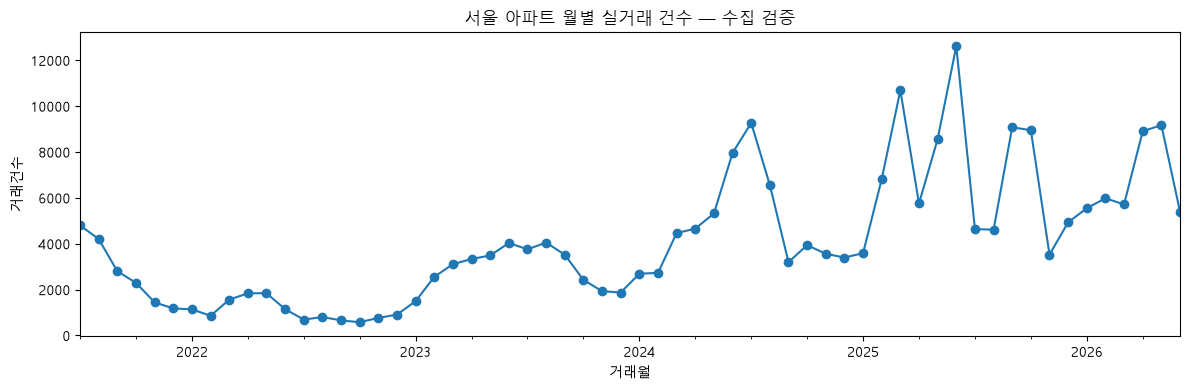

In [27]:
# 연도별/월별 거래량 빠른 확인
if {"계약년도", "계약월"}.issubset(raw_df.columns):
    quick = raw_df.copy()
    quick["계약년도"] = pd.to_numeric(
        quick["계약년도"],
        errors="coerce"
    )
    quick["계약월"] = pd.to_numeric(
        quick["계약월"],
        errors="coerce"
    )

    quick["거래월"] = pd.to_datetime(
        dict(
            year=quick["계약년도"],
            month=quick["계약월"],
            day=1,
        ),
        errors="coerce"
    )

    yearly_counts = (
        quick.groupby(
            quick["거래월"].dt.year
        )
        .size()
    )

    monthly_counts = (
        quick.groupby("거래월")
        .size()
    )

    print("연도별 거래건수:")
    display(yearly_counts)

    monthly_counts.plot(
        figsize=(12, 4),
        marker="o"
    )
    plt.title("서울 아파트 월별 실거래 건수 — 수집 검증")
    plt.ylabel("거래건수")
    plt.tight_layout()
    plt.show()


In [28]:
raw_df.describe(include="all").T.head(30)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
법정동시군구코드,247385,25,11350,19614,NaN,NaN,NaN,NaN,NaN,NaN,NaN
법정동읍면동코드,247385.0,NaN,NaN,NaN,10966.708976,1236.980143,10100.0,10200.0,10600.0,11000.0,18700.0
법정동지번코드,247385.0,NaN,NaN,NaN,1.00091,0.044177,1.0,1.0,1.0,1.0,5.0
법정동본번코드,247385.0,NaN,NaN,NaN,623.004782,614.91482,1.0,230.0,506.0,818.0,4974.0
법정동부번코드,247385.0,NaN,NaN,NaN,5.188265,43.823916,0.0,0.0,0.0,0.0,2837.0
도로명,247385,3376,고덕로,3170,NaN,NaN,NaN,NaN,NaN,NaN,NaN
도로명시군구코드,247215.0,NaN,NaN,NaN,11458.864147,177.765553,11110.0,11305.0,11470.0,11620.0,11740.0
도로명코드,247215.0,NaN,NaN,NaN,3549832.948163,606934.34379,2000003.0,3109002.0,3124001.0,4142002.0,4864430.0
도로명일련번호코드,247232.0,NaN,NaN,NaN,1.368282,1.375911,0.0,1.0,1.0,1.0,27.0
도로명지상지하코드,218880.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 다음 단계

`02_eda_feature_engineering_5year.ipynb`를 실행합니다.

다음 노트북은 우선 `apt_trade_raw_5y.parquet`를 읽고,
파일이 없을 경우에만 `apt_trade_raw.parquet`를 fallback으로 읽도록 구성했습니다.

### 5년 버전에서 추가로 보는 것
- 연도/월/분기별 가격과 거래량
- 구별 가격 추세
- `경과월`, 월 주기형 피처
- 현재 거래가격을 쓰지 않는 **과거 월 기반 가격·거래량 lag 피처**
- 5년 기간에서 현재 인프라 좌표를 과거 거래에 적용하는 한계 문서화
